<a href="https://colab.research.google.com/github/toshniwal-keshav/LabArtificialInteligence/blob/main/Week9_ResolutionFOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

How many clauses are in your Knowledge Base? 5
Enter KB clause #1 (use '|' for OR, '~' for negation): ~Science(x) | Physics(x) | Math(x)
Enter KB clause #2 (use '|' for OR, '~' for negation): ~Math(x) | Stats(x)
Enter KB clause #3 (use '|' for OR, '~' for negation): Science(Alice)
Enter KB clause #4 (use '|' for OR, '~' for negation): Physics(Bob)
Enter KB clause #5 (use '|' for OR, '~' for negation): ~Stats(x) | Data(x)
Enter your Negated Goal clause (e.g., ~Likes(John, Peanuts)): Data(Alice)
The negated goal 'Data(Alice)' is NOT false (Could not resolve to contradiction; original goal cannot be proved).


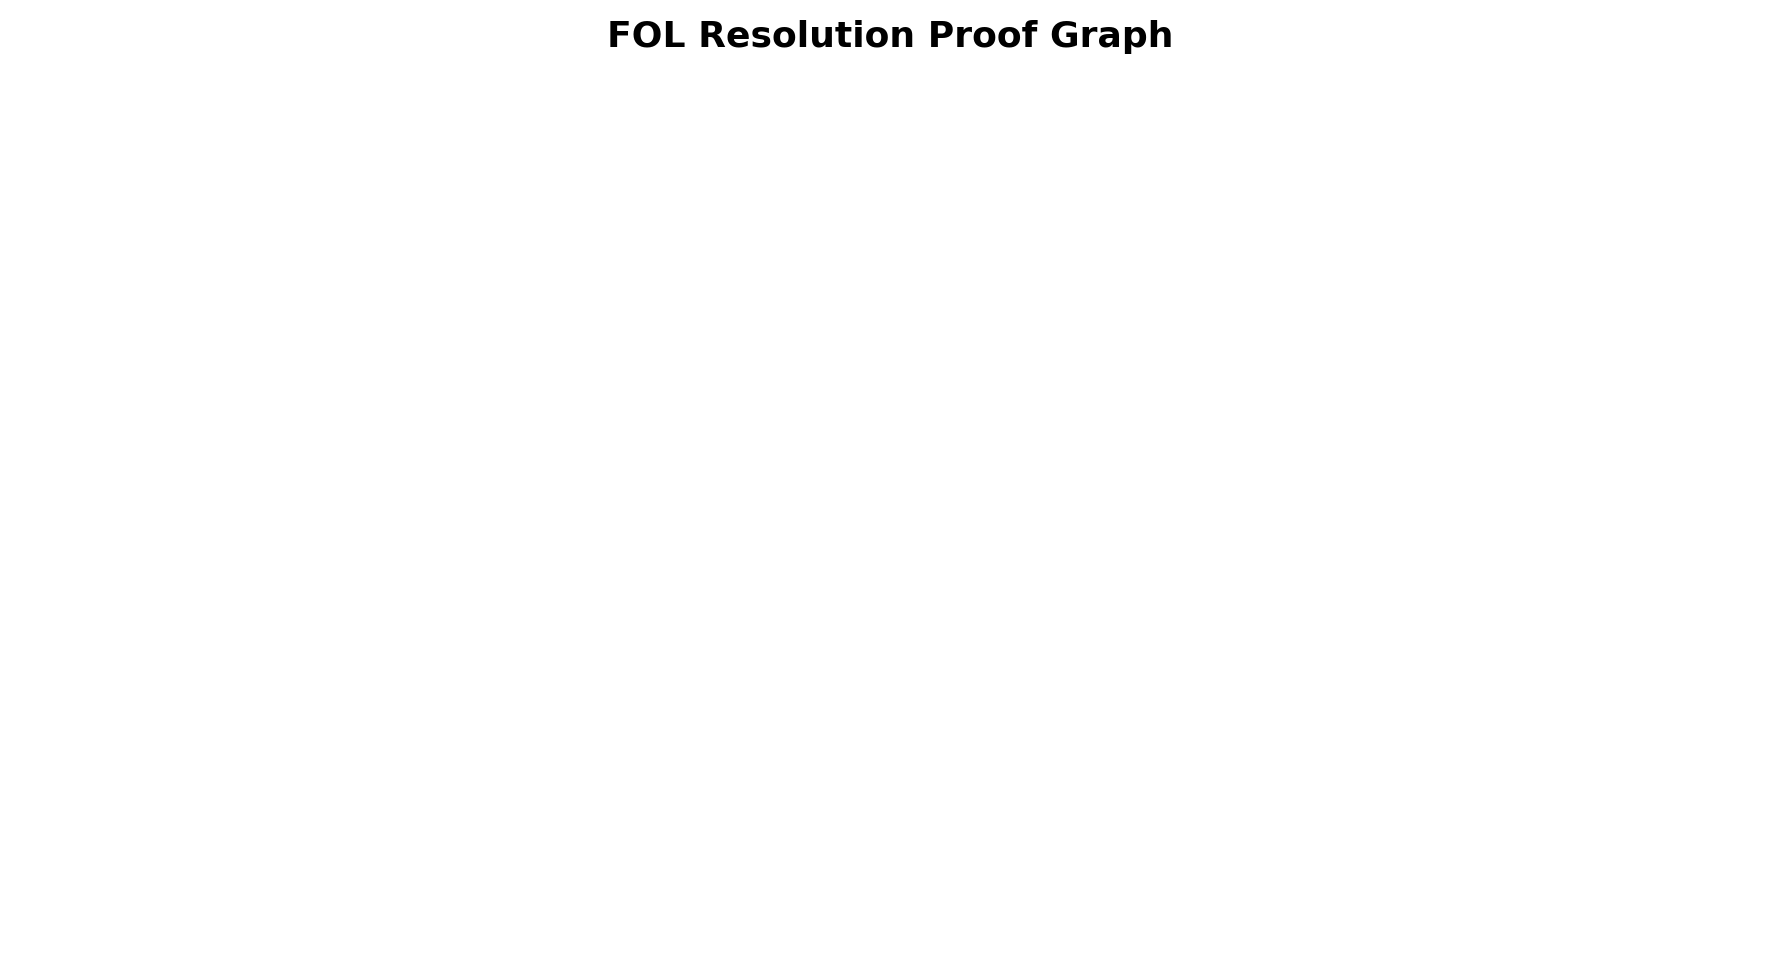

In [9]:
# @title FOL Resolution Prover & Proof Graph
# Prompting user dynamically for interactive inputs
try:
    num_clauses = int(input("How many clauses are in your Knowledge Base? "))
    kb_list = []
    for i in range(num_clauses):
        clause_text = input(f"Enter KB clause #{i+1} (use '|' for OR, '~' for negation): ")
        kb_list.append(clause_text)
    kb_input = "; ".join(kb_list)
except ValueError:
    print("Invalid number. Falling back to default values.")
    kb_input = "~Food(x) | Likes(John, x); Food(Apple); Food(Vegetables); ~Eats(y, z) | Killed(y) | Food(z); Eats(Anil, Peanuts); Alive(Anil); ~Eats(Anil, a) | Eats(Harry, a); ~Alive(b) | ~Killed(b); Killed(c) | Alive(c)"

negated_goal_input = input("Enter your Negated Goal clause (e.g., ~Likes(John, Peanuts)): ")

import matplotlib.pyplot as plt
from IPython.display import Image, display

# --- 1. DATA STRUCTURES ---
class Term:
    def __init__(self, name, args=None):
        self.name = str(name)
        self.args = args if args is not None else []
        self.is_var = (len(self.args) == 0 and self.name.islower())

    def __repr__(self):
        if not self.args:
            return self.name
        return f"{self.name}({', '.join(map(str, self.args))})"

    def __eq__(self, other):
        return isinstance(other, Term) and self.name == other.name and self.args == other.args

    def __hash__(self):
        return hash((self.name, tuple(self.args)))


class Literal:
    def __init__(self, predicate, args, negated=False):
        self.predicate = predicate
        self.args = args
        self.negated = negated

    def __repr__(self):
        prefix = "¬" if self.negated else ""
        return f"{prefix}{self.predicate}({', '.join(map(str, self.args))})"

    def __eq__(self, other):
        return (isinstance(other, Literal) and self.predicate == other.predicate
                and self.negated == other.negated and self.args == other.args)

    def __hash__(self):
        return hash((self.predicate, self.negated, tuple(self.args)))


class ProofNode:
    def __init__(self, clause, parent1=None, parent2=None, subst=None, is_goal=False):
        self.clause = clause
        self.parent1 = parent1
        self.parent2 = parent2
        self.subst = subst or {}
        self.is_goal = is_goal

    def label(self):
        if not self.clause:
            return "{   }   Hence proved."
        cleaned = []
        for lit in self.clause:
            clean_args = [Term(a.name.partition('_')[0]) if a.is_var else a for a in lit.args]
            cleaned.append(str(Literal(lit.predicate, clean_args, lit.negated)))
        return " ∨ ".join(cleaned)

    def subst_label(self):
        if not self.subst:
            return ""
        pairs = []
        for k, v in self.subst.items():
            clean_var = k.name.partition('_')[0]
            clean_val = v.name.partition('_')[0] if v.is_var else str(v)
            pairs.append(f"{clean_val}/{clean_var}")
        return "{" + ", ".join(pairs) + "}"


# --- 2. UNIFICATION ENGINE (MGU) ---
def occur_check(var, term, subst):
    if var == term:
        return True
    if term.is_var and term in subst:
        return occur_check(var, subst[term], subst)
    return any(occur_check(var, arg, subst) for arg in term.args)

def unify(x, y, subst=None):
    if subst is None: subst = {}
    if subst is False: return False
    if x == y: return subst
    if isinstance(x, Term) and x.is_var: return unify_var(x, y, subst)
    if isinstance(y, Term) and y.is_var: return unify_var(y, x, subst)
    if isinstance(x, Term) and isinstance(y, Term):
        if x.name != y.name or len(x.args) != len(y.args): return False
        for a, b in zip(x.args, y.args): subst = unify(a, b, subst)
        return subst
    if isinstance(x, Literal) and isinstance(y, Literal):
        if x.predicate != y.predicate or len(x.args) != len(y.args): return False
        for a, b in zip(x.args, y.args): subst = unify(a, b, subst)
        return subst
    return False

def unify_var(var, x, subst):
    if var in subst: return unify(subst[var], x, subst)
    if isinstance(x, Term) and x.is_var and x in subst: return unify(var, subst[x], subst)
    if occur_check(var, x, subst): return False
    subst[var] = x
    return subst

def apply_subst_term(term, subst):
    if term.is_var and term in subst:
        return apply_subst_term(subst[term], subst)
    return Term(term.name, [apply_subst_term(arg, subst) for arg in term.args])

def apply_subst_literal(lit, subst):
    return Literal(lit.predicate, [apply_subst_term(arg, subst) for arg in lit.args], lit.negated)


# --- 3. RESOLUTION ENGINE ---
def standardize_variables(clause, counter):
    mapping = {}
    def rename(term):
        if term.is_var:
            if term.name not in mapping:
                mapping[term.name] = Term(f"{term.name}_{counter}")
            return mapping[term.name]
        return Term(term.name, [rename(arg) for arg in term.args])
    return [Literal(lit.predicate, [rename(arg) for arg in lit.args], lit.negated) for lit in clause]

def canonical_key(clause):
    mapping = {}
    def norm(term):
        if term.is_var:
            if term.name not in mapping:
                mapping[term.name] = Term(f"v{len(mapping)}")
            return mapping[term.name]
        return Term(term.name, [norm(arg) for arg in term.args])
    normalized = [Literal(lit.predicate, [norm(arg) for arg in lit.args], lit.negated) for lit in clause]
    return frozenset(normalized)

def resolve_nodes(node1, node2, counter):
    c1 = standardize_variables(node1.clause, counter)
    c2 = standardize_variables(node2.clause, counter + 1)
    resolvents = []

    for di in c1:
        for dj in c2:
            if di.predicate == dj.predicate and di.negated != dj.negated:
                subst = unify(di, dj, {})
                if subst is not False:
                    new_c1 = [apply_subst_literal(lit, subst) for lit in c1 if lit != di]
                    new_c2 = [apply_subst_literal(lit, subst) for lit in c2 if lit != dj]
                    resolvent_clause = list(dict.fromkeys(new_c1 + new_c2))

                    used_vars = {arg for lit in (c1 + c2) for arg in lit.args if arg.is_var}
                    step_subst = {k: apply_subst_term(v, subst) for k, v in subst.items() if k in used_vars}
                    resolvents.append(ProofNode(resolvent_clause, node1, node2, step_subst))
    return resolvents

def fol_resolution(kb_clauses, negated_goal_clauses):
    kb_nodes = [ProofNode(c) for c in kb_clauses]
    goal_nodes = [ProofNode(c, is_goal=True) for c in negated_goal_clauses]

    all_nodes = kb_nodes + goal_nodes
    sos_nodes = list(goal_nodes)
    seen_clauses = {canonical_key(n.clause) for n in all_nodes}
    counter = 1

    while sos_nodes:
        current = sos_nodes.pop(0)
        for other in list(all_nodes):
            if current is other:
                continue
            new_nodes = resolve_nodes(current, other, counter)
            counter += 2

            for node in new_nodes:
                if not node.clause:
                    return True, node

                key = canonical_key(node.clause)
                if key not in seen_clauses:
                    seen_clauses.add(key)
                    all_nodes.append(node)
                    sos_nodes.append(node)

    return False, None


# --- 4. RESOLUTION GRAPH VISUALIZER ---
def plot_resolution_tree(goal_proof_node):
    chain = []
    curr = goal_proof_node

    while curr is not None:
        chain.append(curr)
        p1, p2 = curr.parent1, curr.parent2
        if p1 is None and p2 is None:
            break

        p1_is_spine = p1 is not None and (p1.is_goal or p1.parent1 is not None)
        p2_is_spine = p2 is not None and (p2.is_goal or p2.parent1 is not None)

        if p1_is_spine:
            curr = p1
        elif p2_is_spine:
            curr.parent1, curr.parent2 = p2, p1
            curr = p2
        else:
            curr = p1

    chain.reverse()

    fig, ax = plt.subplots(figsize=(9, max(5, len(chain) * 1.35)))
    ax.axis('off')

    x_left = 0.25
    x_right = 0.72
    y_step = 1.0
    y_top = len(chain) * y_step

    for i, node in enumerate(chain):
        y = y_top - i * y_step
        is_first = (i == 0)
        is_last = (i == len(chain) - 1)

        weight = 'bold' if (is_first or is_last) else 'normal'
        fontsize = 11 if is_last else 10
        ax.text(x_left, y, node.label(), ha='center', va='center',
                fontsize=fontsize, fontweight=weight, family='sans-serif')

        if not is_first and node.parent2 is not None:
            y_prev = y_top - (i - 1) * y_step
            right_parent = node.parent2

            ax.text(x_right, y_prev, right_parent.label(), ha='center', va='center',
                    fontsize=10, family='sans-serif')

            subst_text = node.subst_label()
            if subst_text:
                ax.text(x_right + 0.12, y_prev - 0.35, subst_text, ha='center', va='center',
                        fontsize=9, color='#222222', family='sans-serif')

            ax.plot([x_left, x_left], [y_prev - 0.18, y + 0.18], color='black', lw=1.1)
            ax.plot([x_right - 0.05, x_left + 0.02], [y_prev - 0.18, y + 0.18], color='black', lw=1.1)

    ax.set_xlim(0, 1.1)
    ax.set_ylim(0.5, y_top + 0.6)
    plt.title("FOL Resolution Proof Graph", fontsize=13, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.savefig("resolution_graph.png", dpi=200, bbox_inches='tight')
    plt.close(fig)
    display(Image("resolution_graph.png"))


# --- 5. PARSER & EXECUTION ---
def split_args(s):
    args, current, depth = [], [], 0
    for char in s:
        if char == ',' and depth == 0:
            args.append(''.join(current).strip())
            current = []
        else:
            if char == '(': depth += 1
            elif char == ')': depth -= 1
            current.append(char)
    if current:
        args.append(''.join(current).strip())
    return args

def parse_term(s):
    s = s.strip()
    if '(' not in s:
        return Term(s)
    name, rest = s.split('(', 1)
    rest = rest.rstrip(')')
    arg_strs = split_args(rest)
    return Term(name, [parse_term(arg) for arg in arg_strs])

def parse_literal(s):
    s = s.strip()
    negated = False
    if s.startswith('~'):
        negated = True
        s = s[1:].strip()
    elif s.startswith('¬'):
        negated = True
        s = s[1:].strip()

    name, rest = s.split('(', 1)
    rest = rest.rstrip(')')
    arg_strs = split_args(rest)
    return Literal(name, [parse_term(arg) for arg in arg_strs], negated)

def parse_clause(s):
    s = s.strip()
    parts = s.split('|')
    return [parse_literal(p) for p in parts]

# Setup the input lists
kb_clauses = [parse_clause(c) for c in kb_input.split(';') if c.strip()]
negated_goal_clauses = [parse_clause(c) for c in negated_goal_input.split(';') if c.strip()]

success, final_node = fol_resolution(kb_clauses, negated_goal_clauses)
if success:
    print(f"The negated goal '{negated_goal_input}' is FALSE (A contradiction was reached, proving the original goal is TRUE).")
    plot_resolution_tree(final_node)
else:
    print(f"The negated goal '{negated_goal_input}' is NOT false (Could not resolve to contradiction; original goal cannot be proved).")
    # plot_resolution_tree(final_node)